# Import Modules

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, PowerTransformer, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc, \
    ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import GridSearchCV

In [5]:
from sklearn import set_config

set_config(display='diagram')

# Reading the Dataset

In [6]:
df = pd.read_csv('./data/Telco-Customer-Churn.csv')
df = df.drop(columns=['customerID'], axis=1)

In [7]:
df.sample(7)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
419,Female,1,No,No,1,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,Yes,Bank transfer (automatic),75.30,75.3,Yes
566,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,Yes,Yes,Yes,One year,No,Electronic check,101.90,1667.25,No
6237,Male,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Electronic check,69.95,69.95,Yes
1407,Male,0,No,Yes,8,No,No phone service,DSL,Yes,No,No,Yes,No,Yes,Two year,Yes,Mailed check,44.55,343.45,No
4021,Female,0,Yes,Yes,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.50,20.5,Yes
2910,Female,0,Yes,Yes,35,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Credit card (automatic),25.40,949.8,No
810,Male,0,No,No,58,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Bank transfer (automatic),103.25,6017.65,Yes


## How big is the Data?

In [8]:
rows = df.shape[0]
cols = df.shape[1]
print(f"Dataset have {rows} rows, {cols} columns.")

Dataset have 7043 rows, 20 columns.


## What is the Data-Type of Columns?

In [9]:
df.dtypes

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

## Are there any Missing Values in the Dataset?

In [10]:
df.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## How does the Data look Mathematically?

In [11]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## Are there any Duplicate Values?

In [12]:
print(f"There are {df.duplicated().sum()} duplicated rows in the dataset.")

There are 22 duplicated rows in the dataset.


In [13]:
df = df.drop_duplicates().reset_index(drop=True)

In [14]:
rows = df.shape[0]
cols = df.shape[1]
print(f"Data has {rows} rows, {cols} columns.")

Data has 7021 rows, 20 columns.


## Correlation between Numerical Columns

In [15]:
corr = df.corr(numeric_only=True)
corr

,SeniorCitizen,tenure,MonthlyCharges
SeniorCitizen,1.000000,0.015349,0.219434
tenure,0.015349,1.000000,0.245251
MonthlyCharges,0.219434,0.245251,1.000000


# Data Manipulation

There is ' ' in some colums.
Their tenure is also 0.

In [16]:
error_rows = df[pd.isna(pd.to_numeric(df['TotalCharges'], errors='coerce'))]
error_rows

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1081,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1338,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3323,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3817,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4370,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5207,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6652,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [17]:
df.drop(labels=error_rows.index, axis=0, inplace=True)

In [18]:
rows = df.shape[0]
cols = df.shape[1]
print(f"Data has {rows} rows, {cols} columns.")

Data has 7010 rows, 20 columns.


In [19]:
df['TotalCharges'] = df['TotalCharges'].astype('float')
df['TotalCharges'].dtype

dtype('float64')

SeniorCitizen column to object

In [20]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df['SeniorCitizen'].value_counts()

SeniorCitizen
No     5869
Yes    1141
Name: count, dtype: int64

InternetService and PhoneService are seperate columns so no need for mentioning no internet service or no phone service in other columns

In [21]:
mentioning_cols = [
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
]

In [22]:
df[mentioning_cols] = df[mentioning_cols].replace({
    'No internet service': 'No',
    'No phone service': 'No'
})

In [23]:
for col in mentioning_cols:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())


Column: MultipleLines
MultipleLines
No     4043
Yes    2967
Name: count, dtype: int64

Column: OnlineSecurity
OnlineSecurity
No     4995
Yes    2015
Name: count, dtype: int64

Column: OnlineBackup
OnlineBackup
No     4585
Yes    2425
Name: count, dtype: int64

Column: DeviceProtection
DeviceProtection
No     4592
Yes    2418
Name: count, dtype: int64

Column: TechSupport
TechSupport
No     4970
Yes    2040
Name: count, dtype: int64

Column: StreamingTV
StreamingTV
No     4307
Yes    2703
Name: count, dtype: int64

Column: StreamingMovies
StreamingMovies
No     4279
Yes    2731
Name: count, dtype: int64


# Exploratory Data Analysis (EDA)

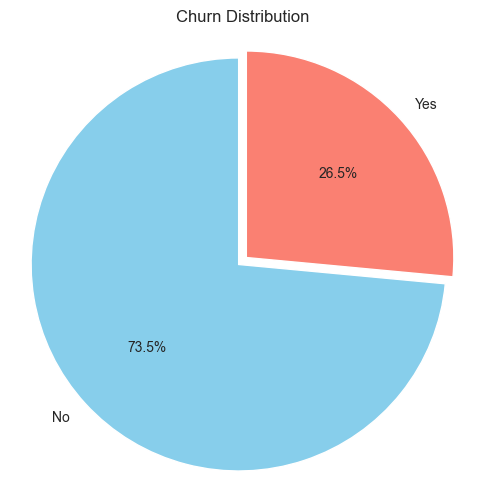

In [24]:
churn_counts = df['Churn'].value_counts()
churn_labels = churn_counts.index
churn_sizes = churn_counts.values
colors = ['skyblue', 'salmon']

plt.figure(figsize=(6, 6))
plt.pie(churn_sizes, labels=churn_labels, autopct='%1.1f%%', startangle=90, colors=colors, explode=[0.05, 0])
plt.title("Churn Distribution")
plt.axis('equal')
plt.show()

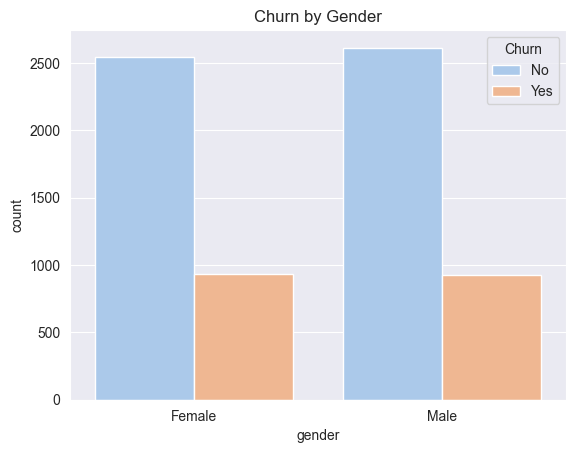

In [25]:
sns.countplot(x='gender', hue='Churn', data=df, palette='pastel')
plt.title('Churn by Gender')
plt.show()

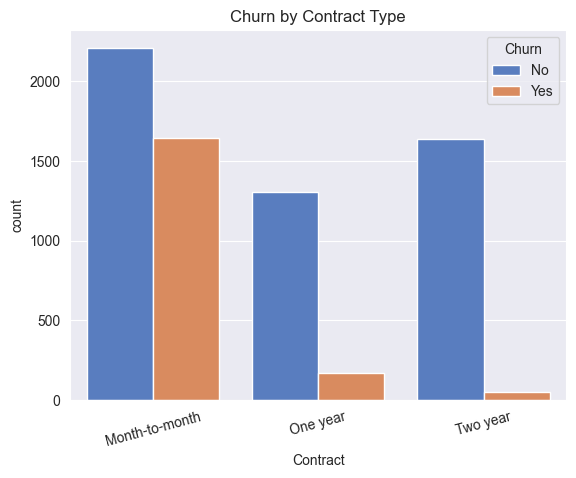

In [26]:
sns.countplot(x='Contract', hue='Churn', data=df, palette='muted')
plt.title('Churn by Contract Type')
plt.xticks(rotation=15)
plt.show()

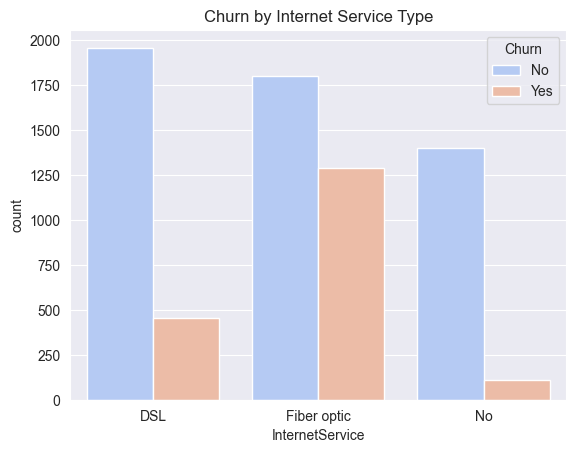

In [27]:
sns.countplot(x='InternetService', hue='Churn', data=df, palette='coolwarm')
plt.title('Churn by Internet Service Type')
plt.show()

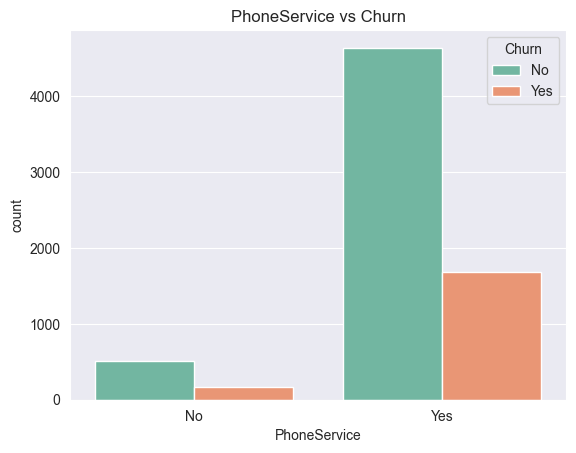

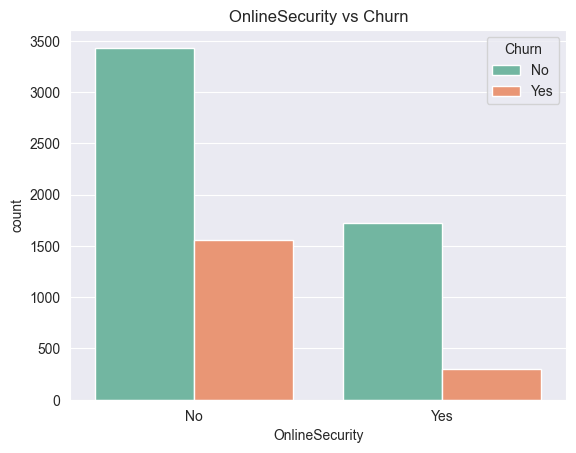

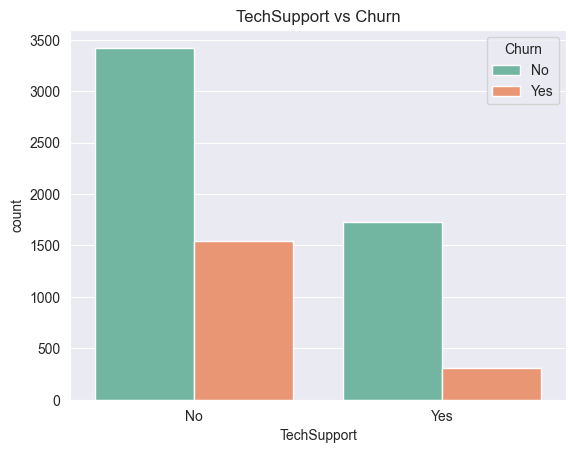

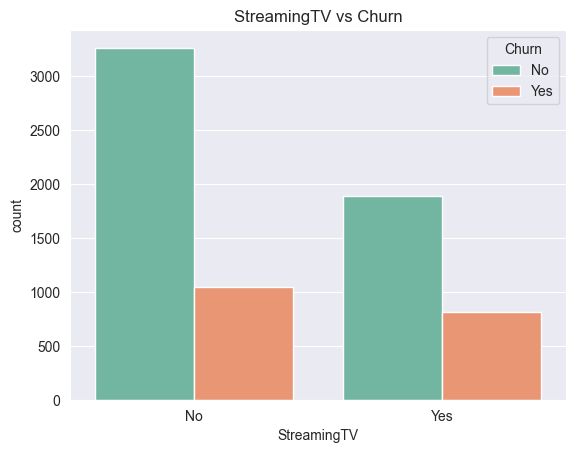

In [28]:
features = ['PhoneService', 'OnlineSecurity', 'TechSupport', 'StreamingTV']
for feature in features:
    sns.countplot(x=feature, hue='Churn', data=df, palette='Set2')
    plt.title(f'{feature} vs Churn')
    plt.xticks()
    plt.show()

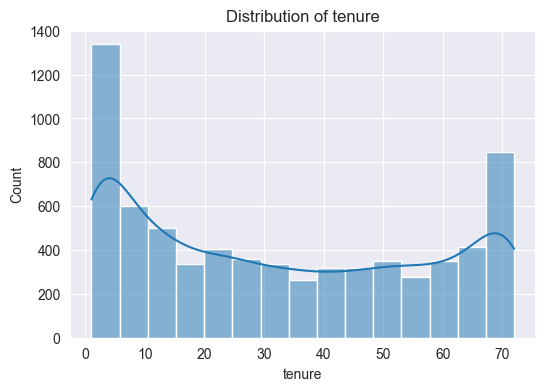

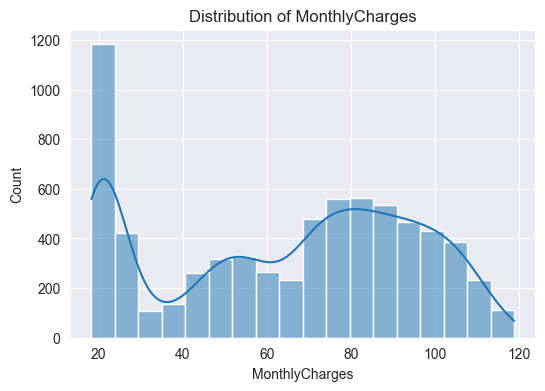

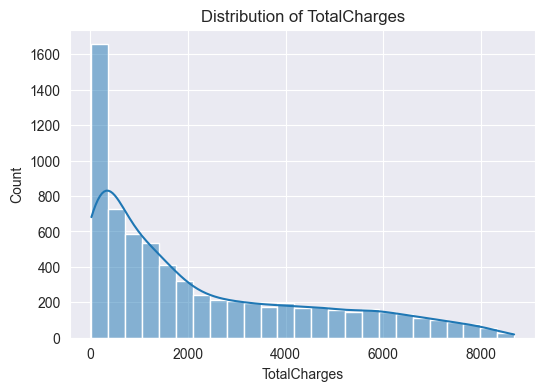

In [29]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in numerical_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()


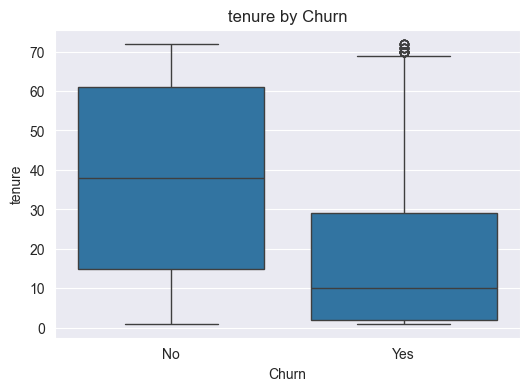

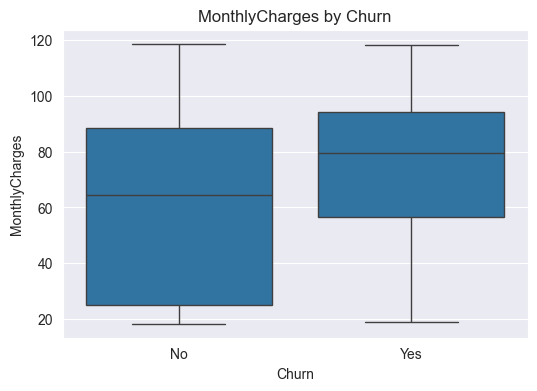

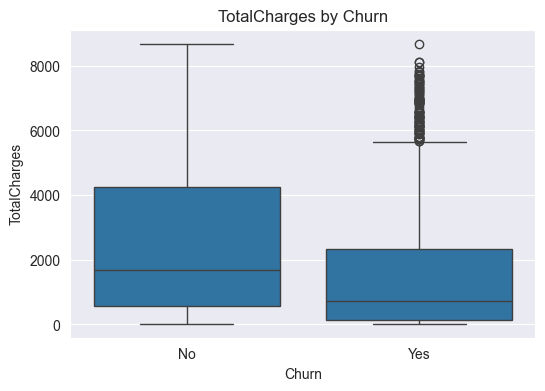

In [30]:
for col in numerical_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x='Churn', y=col, data=df)
    plt.title(f'{col} by Churn')
    plt.show()

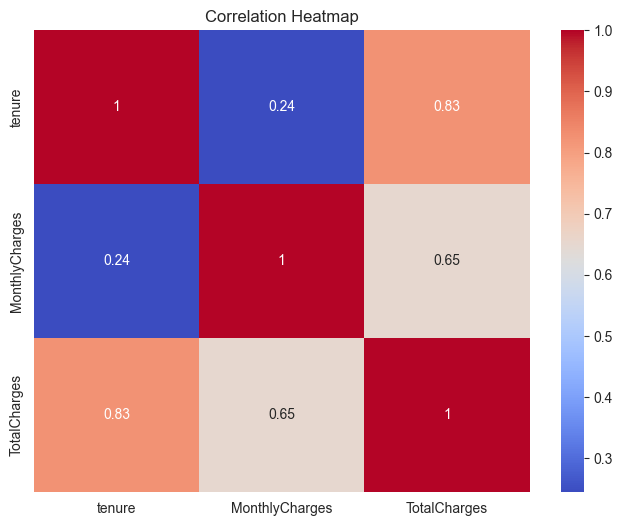

In [31]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

# Data Preprocessing

In [32]:
X = df.drop(columns='Churn')
y = df['Churn']
y = y.map({'Yes': 1, 'No': 0})

In [33]:
yes_no_cols = [
    'SeniorCitizen',
    'Partner',
    'Dependents',
    'PhoneService',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'PaperlessBilling',
]

In [34]:
categorical_cols = [
    'gender',
    'InternetService',
    'Contract',
    'PaymentMethod',
]

In [35]:
numerical_cols = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges',
]

In [36]:
def yes_no_to_binary_transformer(x):
    return (x == 'Yes').astype(int)

In [37]:
yes_no_transformer = FunctionTransformer(yes_no_to_binary_transformer, validate=False)

In [38]:
preprocessor = ColumnTransformer(transformers=[
    ('binary_transformer', yes_no_transformer, yes_no_cols),
    ('tenure_transformer', PowerTransformer(method='yeo-johnson'), ['tenure']),
    ('monthly_charges_transformer', StandardScaler(), ['MonthlyCharges']),
    ('total_charges_transformer', PowerTransformer(method='yeo-johnson'), ['TotalCharges']),
    ('categorical_transformer', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), categorical_cols)
], remainder='passthrough')

# Machine Learning Models

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

Logistic Regression

In [40]:
lr_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42)),
])

In [41]:
lr_pipe.fit(X_train, y_train)
y_pred = lr_pipe.predict(X_test)
lr_accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", lr_accuracy)

Accuracy: 0.8145506419400856


Support Vector Classifier

In [42]:
svc_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(random_state=42)),
])

In [43]:
svc_pipe.fit(X_train, y_train)
y_pred = svc_pipe.predict(X_test)
svc_accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", svc_accuracy)

Accuracy: 0.8040893961008083


Gradient Boost

In [44]:
gb_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

In [45]:
gb_pipe.fit(X_train, y_train)
y_pred = gb_pipe.predict(X_test)
gb_accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", gb_accuracy)

Accuracy: 0.8059914407988588


ROC Curve

In [46]:
y_pred = lr_pipe.predict(X_test)
y_probs = lr_pipe.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

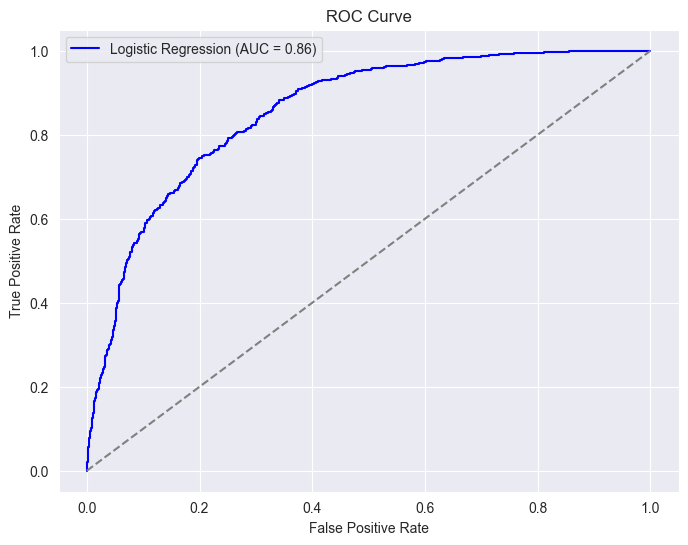

In [47]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.2f})', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

Confusion Matrix

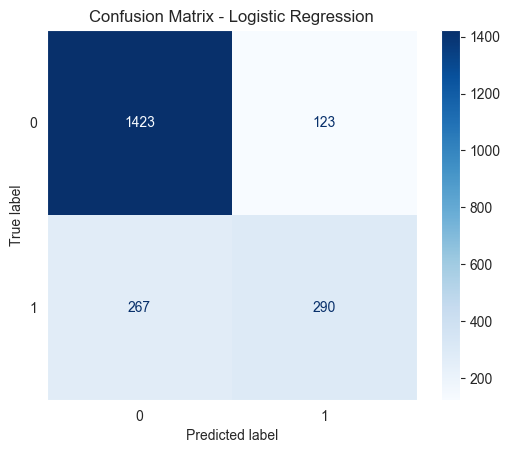

In [48]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Logistic Regression")
plt.grid(False)
plt.show()

Classification Report

In [49]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.92      0.88      1546
           1       0.70      0.52      0.60       557

    accuracy                           0.81      2103
   macro avg       0.77      0.72      0.74      2103
weighted avg       0.80      0.81      0.80      2103



In [50]:
import joblib

joblib.dump(lr_pipe, 'logistic_model_pipeline.pkl')

['logistic_model_pipeline.pkl']